# Transfer learning y fine-tuning en CIFAR-10

El cuaderno ejecuta nueve configuraciones sobre 45 000 imágenes, escoge modelos exclusivamente con validación, y compara los seleccionados con un nuevo entrenamiento sobre 4 500 imágenes. Se usa la semilla 42 y la partición oficial de 10 000 imágenes se reserva para test. Las salidas se generan al ejecutar las celdas en orden desde la raíz del proyecto.

## Investigación de PyTorch

`vgg16(weights=VGG16_Weights.IMAGENET1K_V1)` carga los pesos preentrenados. `VGG16_Weights.IMAGENET1K_V1.transforms()` ofrece reescalado, recorte y normalización de referencia. Se conserva la normalización ImageNet, pero se redimensiona a 112×112 en ambas VGG para limitar el cómputo. `features` contiene cinco bloques convolucionales, `avgpool` es `nn.AdaptiveAvgPool2d((7, 7))` y `classifier` contiene las capas densas. Se sustituye `classifier[6]` por una salida de diez clases.

`requires_grad=False` congela los parámetros del backbone; con un bloque o dos descongelados, los grupos de parámetros del optimizador asignan `backbone_lr` a estos y `lr` al clasificador. `model.train()` activa dropout y la actualización de batch normalization; `model.eval()` desactiva dropout y usa las estadísticas aprendidas. En evaluación, `torch.set_grad_enabled(False)` tiene el mismo propósito de no guardar el grafo que `torch.no_grad()`.

`torch.profiler.profile(with_flops=True)` estima operaciones por imagen para convoluciones y matrices. Un MAC reúne una multiplicación y una suma, aproximadamente dos FLOPs; no todas las operaciones están cubiertas. Los parámetros totales incluyen los congelados, mientras que los entrenables tienen `requires_grad=True`. `torch.cuda.synchronize()` termina las operaciones GPU pendientes antes de medir tiempo; `torch.cuda.max_memory_allocated()` lee el pico de memoria de tensores desde el último reinicio del contador.

## Datos y preparación

CIFAR-10 contiene 50 000 imágenes originales de entrenamiento y 10 000 de test, de 32×32 píxeles RGB. Cada una de las diez clases tiene 5 000 ejemplos de entrenamiento. Se separan 45 000 para entrenar y 5 000 para validar, estratificados por clase. La media y desviación estándar por canal se calculan solo sobre entrenamiento y se imprimen junto a las de ImageNet. Gato/perro, automóvil/camión y ciervo/caballo pueden confundirse por sus siluetas y su baja resolución.

La CNN conserva 32×32 y normaliza con estadísticas de CIFAR-10. VGG usa 112×112 y normalización ImageNet. Pasar de 32 a 112 multiplica por 12,25 el número de píxeles; usar 224 lo multiplicaría por 49. El aumento de datos usa recorte aleatorio con relleno y reflejo horizontal para variar posiciones y orientación. Solo se aplica en entrenamiento, ya que validación y test deben medir imágenes originales sin cambios aleatorios.

In [1]:
import gc
import json
import os
import time
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import VGG16_Weights, vgg16


ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
os.environ["TORCH_HOME"] = str(DATA / "torch")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
SIZE = 112
SEED = 42


def prepare():
    torch.manual_seed(SEED)
    np.random.seed(SEED)
    torch.set_num_threads(4)
    if DEVICE.type == "cuda":
        torch.backends.cudnn.benchmark = True
    RESULTS.mkdir(exist_ok=True)
    raw = datasets.CIFAR10(root=DATA, train=True, download=True)
    test = datasets.CIFAR10(root=DATA, train=False, download=True)
    indices = np.arange(len(raw))
    train, val = train_test_split(indices, test_size=5000, stratify=raw.targets, random_state=SEED)
    reduced, _ = train_test_split(train, train_size=0.1, stratify=np.asarray(raw.targets)[train], random_state=SEED)
    pixels = raw.data.astype(np.float64) / 255
    stats = {
        "observations": {"original_train": len(raw), "train": len(train), "validation": len(val), "test": len(test)},
        "classes": raw.classes,
        "counts": {name: int(sum(np.asarray(raw.targets) == i)) for i, name in enumerate(raw.classes)},
        "train_mean": pixels[train].mean(axis=(0, 1, 2)).tolist(),
        "train_std": pixels[train].std(axis=(0, 1, 2)).tolist(),
        "imagenet_mean": IMAGENET_MEAN,
        "imagenet_std": IMAGENET_STD,
        "input_shape": list(raw.data.shape[1:]),
        "pixel_multiplier": (SIZE / 32) ** 2,
        "device": str(DEVICE),
        "hardware": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU",
    }
    (RESULTS / "dataset.json").write_text(json.dumps(stats, indent=2, ensure_ascii=False), encoding="utf-8")
    fig, axes = plt.subplots(10, 5, figsize=(9, 15))
    for i, name in enumerate(raw.classes):
        for j, index in enumerate(np.flatnonzero(np.asarray(raw.targets) == i)[:5]):
            axes[i, j].imshow(raw.data[index])
            axes[i, j].axis("off")
            if j == 0:
                axes[i, j].set_title(name)
    fig.tight_layout()
    fig.savefig(RESULTS / "examples.png", dpi=130)
    plt.close(fig)
    return train, val, reduced, raw.classes


def loaders(kind, train_indices, val_indices, batch_size):
    if kind == "cnn":
        train_transform = transforms.Compose([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize(MEAN, STD),
        ])
        eval_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    else:
        train_transform = transforms.Compose([
            transforms.Resize((SIZE, SIZE)),
            transforms.RandomCrop(SIZE, padding=4),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])
        eval_transform = transforms.Compose([
            transforms.Resize((SIZE, SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])
    training = Subset(datasets.CIFAR10(root=DATA, train=True, transform=train_transform), train_indices)
    validation = Subset(datasets.CIFAR10(root=DATA, train=True, transform=eval_transform), val_indices)
    test = datasets.CIFAR10(root=DATA, train=False, transform=eval_transform)
    kwargs = {"batch_size": batch_size, "num_workers": 0, "pin_memory": DEVICE.type == "cuda"}
    return (
        DataLoader(training, shuffle=len(train_indices) > 0, **kwargs),
        DataLoader(validation, shuffle=False, **kwargs),
        DataLoader(test, shuffle=False, **kwargs),
    )


class SmallCNN(nn.Module):
    def __init__(self, width=32, dropout=0.3):
        super().__init__()
        layers = []
        channels = 3
        for output in (width, width * 2, width * 4):
            layers.extend([
                nn.Conv2d(channels, output, 3, padding=1),
                nn.BatchNorm2d(output),
                nn.ReLU(),
                nn.Conv2d(output, output, 3, padding=1),
                nn.BatchNorm2d(output),
                nn.ReLU(),
                nn.MaxPool2d(2),
            ])
            channels = output
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(channels, 10))

    def forward(self, images):
        return self.classifier(self.features(images))


def create_model(config):
    if config["kind"] == "cnn":
        model = SmallCNN(config["width"], config["dropout"])
        groups = [{"params": model.parameters(), "lr": config["lr"]}]
    else:
        model = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, 10)
        for param in model.features.parameters():
            param.requires_grad = False
        blocks = config["blocks"]
        if blocks:
            start = {1: 24, 2: 17, 3: 10}[blocks]
            for param in model.features[start:].parameters():
                param.requires_grad = True
        groups = [
            {"params": model.classifier.parameters(), "lr": config["lr"]},
        ]
        if blocks:
            groups.append({"params": [p for p in model.features.parameters() if p.requires_grad], "lr": config["backbone_lr"]})
    return model.to(DEVICE), groups


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def metrics(labels, predictions):
    precision, recall, f1, _ = precision_recall_fscore_support(labels, predictions, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(labels, predictions), "precision": precision, "recall": recall, "f1": f1}


def epoch(model, loader, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    criterion = nn.CrossEntropyLoss()
    total = 0
    labels, predictions = [], []
    loss_sum = 0.0
    for images, targets in loader:
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                output = model(images)
                loss = criterion(output, targets)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
        total += targets.size(0)
        loss_sum += loss.item() * targets.size(0)
        labels.extend(targets.cpu().tolist())
        predictions.extend(output.argmax(1).cpu().tolist())
    return {"loss": loss_sum / total, **metrics(labels, predictions)}, labels, predictions


def run(config, train_indices, val_indices, classes, reduced=False):
    name = config["name"] + ("_10pct" if reduced else "")
    output = RESULTS / f"{name}.json"
    if output.exists() and (RESULTS / f"{name}.pt").exists():
        print("Already completed:", name, flush=True)
        return json.loads(output.read_text(encoding="utf-8"))
    torch.manual_seed(SEED)
    model, groups = create_model(config)
    training, validation, _ = loaders(config["kind"], train_indices, val_indices, config["batch"])
    optimizer = torch.optim.SGD(groups, momentum=0.9, weight_decay=1e-4)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    history = []
    synchronize()
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    best_f1 = -1
    for number in range(config["epochs"]):
        before = time.perf_counter()
        train_values, _, _ = epoch(model, training, optimizer, scaler)
        synchronize()
        seconds = time.perf_counter() - before
        val_values, _, _ = epoch(model, validation)
        synchronize()
        history.append({"epoch": number + 1, "train": train_values, "validation": val_values, "train_seconds": seconds, "elapsed_seconds": time.perf_counter() - start})
        if val_values["f1"] > best_f1:
            best_f1 = val_values["f1"]
            torch.save(model.state_dict(), RESULTS / f"{name}.pt")
        print(name, number + 1, f"train={train_values['loss']:.4f}", f"val_f1={val_values['f1']:.4f}", f"seconds={seconds:.1f}", flush=True)
    best = max(history, key=lambda item: item["validation"]["f1"])
    synchronize()
    peak = torch.cuda.max_memory_allocated() if DEVICE.type == "cuda" else None
    result = {
        "config": config, "reduced": reduced, "train_images": len(train_indices), "history": history,
        "selected_epoch": best["epoch"], "best_validation": best["validation"],
        "classes": classes,
        "total_params": total_params, "trainable_params": trainable_params,
        "total_seconds": time.perf_counter() - start, "peak_gpu_bytes": peak,
    }
    output.write_text(json.dumps(result, indent=2), encoding="utf-8")
    del model, optimizer, scaler, training, validation
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result


def evaluate_selected(config, classes, reduced=False):
    name = config["name"] + ("_10pct" if reduced else "")
    output = RESULTS / f"{name}.json"
    result = json.loads(output.read_text(encoding="utf-8"))
    if "test" in result:
        return result
    model, _ = create_model(config)
    model.load_state_dict(torch.load(RESULTS / f"{name}.pt", map_location=DEVICE, weights_only=True))
    _, _, test = loaders(config["kind"], [], [], config["batch"])
    values, labels, predictions = epoch(model, test)
    result["test"] = values
    result["confusion"] = confusion_matrix(labels, predictions).tolist()
    if not reduced:
        from torch.profiler import ProfilerActivity, profile

        size = 32 if config["kind"] == "cnn" else SIZE
        image = torch.randn(1, 3, size, size, device=DEVICE)
        model.eval()
        with torch.no_grad():
            with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA] if DEVICE.type == "cuda" else [ProfilerActivity.CPU], with_flops=True) as recording:
                model(image)
            result["inference_flops"] = sum(event.flops for event in recording.key_averages())
            frozen_flops = 0
            if config["kind"] != "cnn":
                frozen_end = {0: 31, 1: 24, 2: 17, 3: 10}[config["blocks"]]
                with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA] if DEVICE.type == "cuda" else [ProfilerActivity.CPU], with_flops=True) as frozen_recording:
                    model.features[:frozen_end](image)
                frozen_flops = sum(event.flops for event in frozen_recording.key_averages())
            for _ in range(10):
                model(image)
            synchronize()
            before = time.perf_counter()
            for _ in range(100):
                model(image)
            synchronize()
            result["inference_ms"] = (time.perf_counter() - before) * 10
        result["training_flops_estimate"] = int(result["train_images"] * len(result["history"]) * (3 * result["inference_flops"] - 2 * frozen_flops))
    output.write_text(json.dumps(result, indent=2), encoding="utf-8")
    del model
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return result


CONFIGS = [
    {"name": "cnn_a", "kind": "cnn", "width": 24, "dropout": 0.2, "lr": 0.03, "epochs": 3, "batch": 128},
    {"name": "cnn_b", "kind": "cnn", "width": 32, "dropout": 0.3, "lr": 0.03, "epochs": 3, "batch": 128},
    {"name": "cnn_c", "kind": "cnn", "width": 32, "dropout": 0.4, "lr": 0.01, "epochs": 3, "batch": 128},
    {"name": "extract_a", "kind": "extract", "blocks": 0, "lr": 0.003, "epochs": 2, "batch": 32},
    {"name": "extract_b", "kind": "extract", "blocks": 0, "lr": 0.001, "epochs": 2, "batch": 32},
    {"name": "extract_c", "kind": "extract", "blocks": 0, "lr": 0.0003, "epochs": 2, "batch": 32},
    {"name": "tune_a", "kind": "tune", "blocks": 1, "lr": 0.001, "backbone_lr": 0.0001, "epochs": 2, "batch": 16},
    {"name": "tune_b", "kind": "tune", "blocks": 2, "lr": 0.001, "backbone_lr": 0.0001, "epochs": 2, "batch": 16},
    {"name": "tune_c", "kind": "tune", "blocks": 1, "lr": 0.0003, "backbone_lr": 0.00003, "epochs": 2, "batch": 16},
]


def main():
    train, val, reduced, classes = prepare()
    for config in CONFIGS:
        run(config, train, val, classes)
    winners = {}
    for kind in ("cnn", "extract", "tune"):
        candidates = [json.loads((RESULTS / f"{c['name']}.json").read_text(encoding="utf-8")) for c in CONFIGS if c["kind"] == kind]
        winner = max(candidates, key=lambda item: item["best_validation"]["f1"])
        winners[kind] = winner["config"]["name"]
        evaluate_selected(winner["config"], classes)
        run(winner["config"], reduced, val, classes, reduced=True)
        evaluate_selected(winner["config"], classes, reduced=True)
    (RESULTS / "winners.json").write_text(json.dumps(winners, indent=2), encoding="utf-8")


def plot_results():
    runs = [json.loads((RESULTS / f"{c['name']}.json").read_text(encoding="utf-8")) for c in CONFIGS]
    winners = json.loads((RESULTS / "winners.json").read_text(encoding="utf-8"))
    for kind in ("cnn", "extract", "tune"):
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        for result in runs:
            if result["config"]["kind"] != kind:
                continue
            epochs = [entry["epoch"] for entry in result["history"]]
            for ax, key, title in zip(axes, ("train", "validation"), ("Entrenamiento", "Validación")):
                ax.plot(epochs, [entry[key]["loss"] for entry in result["history"]], marker="o", label=result["config"]["name"])
                ax.set_title(title)
                ax.set_xlabel("Época")
                ax.set_ylabel("Pérdida")
                ax.legend(fontsize=7)
        fig.tight_layout()
        fig.savefig(RESULTS / f"loss_{kind}.png", dpi=140)
        plt.close(fig)
    fig, ax = plt.subplots(figsize=(8, 5))
    for kind, name in winners.items():
        result = next(item for item in runs if item["config"]["name"] == name)
        ax.plot(np.cumsum([entry["train_seconds"] for entry in result["history"]]) / 60,
                [entry["validation"]["accuracy"] for entry in result["history"]], marker="o", label=kind)
    ax.set(xlabel="Tiempo acumulado de entrenamiento (min)", ylabel="Accuracy de validación")
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS / "accuracy_vs_time.png", dpi=140)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(8, 5))
    for kind, name in winners.items():
        result = next(item for item in runs if item["config"]["name"] == name)
        ax.scatter(result["inference_flops"] / 1e9, result["test"]["f1"], label=kind, s=70)
    ax.set(xlabel="GFLOPs por imagen (inferencia)", ylabel="F1 macro de test")
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS / "f1_vs_flops.png", dpi=140)
    plt.close(fig)
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for ax, (kind, name) in zip(axes, winners.items()):
        result = next(item for item in runs if item["config"]["name"] == name)
        ax.imshow(result["confusion"], cmap="Blues")
        ax.set(title=kind, xlabel="Predicción", ylabel="Real", xticks=range(10), yticks=range(10))
        ax.set_xticklabels(result["classes"], rotation=90, fontsize=6)
        ax.set_yticklabels(result["classes"], fontsize=6)
    fig.tight_layout()
    fig.savefig(RESULTS / "confusions.png", dpi=140)
    plt.close(fig)




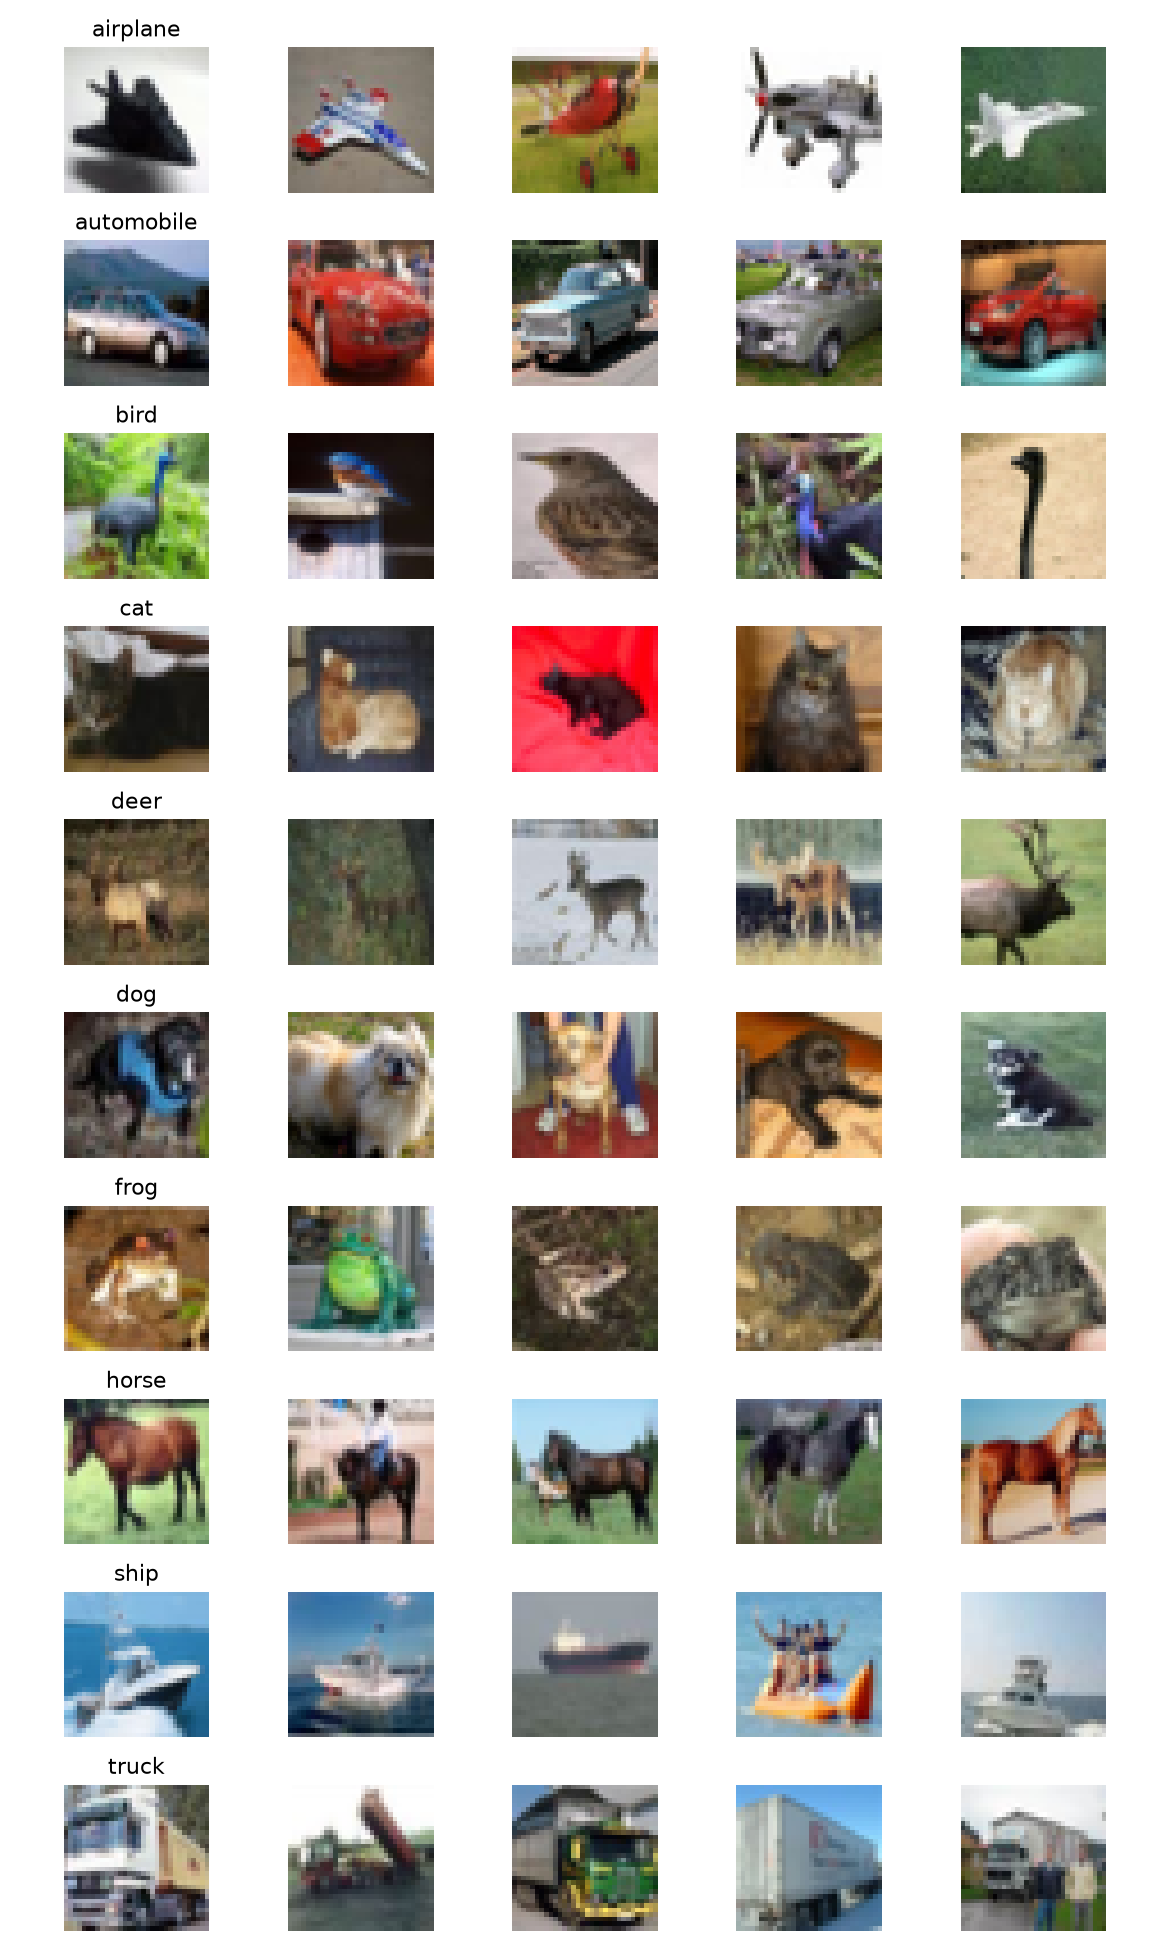

{
  "observations": {
    "original_train": 50000,
    "train": 45000,
    "validation": 5000,
    "test": 10000
  },
  "classes": [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
  ],
  "counts": {
    "airplane": 5000,
    "automobile": 5000,
    "bird": 5000,
    "cat": 5000,
    "deer": 5000,
    "dog": 5000,
    "frog": 5000,
    "horse": 5000,
    "ship": 5000,
    "truck": 5000
  },
  "train_mean": [
    0.49113735123911295,
    0.48211118702342115,
    0.4464489876089326
  ],
  "train_std": [
    0.24686913619557826,
    0.24343012612627368,
    0.2616033939151677
  ],
  "imagenet_mean": [
    0.485,
    0.456,
    0.406
  ],
  "imagenet_std": [
    0.229,
    0.224,
    0.225
  ],
  "input_shape": [
    32,
    32,
    3
  ],
  "pixel_multiplier": 12.25,
  "device": "cuda",
  "hardware": "NVIDIA GeForce RTX 4050 Laptop GPU"
}


In [2]:
train, val, reduced, classes = prepare()
from IPython.display import display, Image
display(Image(filename=str(RESULTS / 'examples.png')))
print((RESULTS / 'dataset.json').read_text(encoding='utf-8'))

## Entrenamiento

La CNN propia contiene tres bloques convolucionales con batch normalization y dropout. La extracción congela los cinco bloques VGG; el fine-tuning compara uno y dos bloques descongelados con una tasa de aprendizaje menor para el backbone. Cada configuración registra pérdida y accuracy, precision, recall y F1 macro en cada época, además de tiempo y memoria. La mejor época se conserva por F1 macro de validación. El test no participa en la selección.

In [3]:
for config in CONFIGS:
    run(config, train, val, classes)

Already completed: cnn_a


Already completed: cnn_b


Already completed: cnn_c


Already completed: extract_a


Already completed: extract_b


Already completed: extract_c


Already completed: tune_a


Already completed: tune_b


Already completed: tune_c


## Evaluación final y recursos

Solo las tres configuraciones seleccionadas se evalúan sobre test. Luego se entrenan nuevamente desde cero para la CNN o desde ImageNet para VGG, con un 10 % estratificado del conjunto de entrenamiento. Para el costo estimado se usa, por imagen y por todas las épocas efectivamente entrenadas, un forward de la parte congelada y tres veces el forward de la parte entrenable. Esta cifra y los FLOPs del profiler son aproximaciones, no un recuento exacto de todas las operaciones.

In [4]:
winners = {}
for kind in ('cnn', 'extract', 'tune'):
    candidates = [json.loads((RESULTS / f"{c['name']}.json").read_text(encoding='utf-8')) for c in CONFIGS if c['kind'] == kind]
    winner = max(candidates, key=lambda item: item['best_validation']['f1'])
    winners[kind] = winner['config']['name']
    evaluate_selected(winner['config'], classes)
    run(winner['config'], reduced, val, classes, reduced=True)
    evaluate_selected(winner['config'], classes, reduced=True)
(RESULTS / 'winners.json').write_text(json.dumps(winners, indent=2), encoding='utf-8')
plot_results()
print(winners)

Already completed: cnn_a_10pct


Already completed: extract_a_10pct


Already completed: tune_b_10pct


{'cnn': 'cnn_a', 'extract': 'extract_a', 'tune': 'tune_b'}


In [5]:
print('Iteración | F1 validación | Época | Parámetros totales / entrenables | Tiempo total (s) | Pico GPU (GiB)')
for config in CONFIGS:
    result = json.loads((RESULTS / f"{config['name']}.json").read_text(encoding='utf-8'))
    peak = result['peak_gpu_bytes'] / 2**30 if result['peak_gpu_bytes'] else 0
    print(f"{config['name']:10s} {result['best_validation']['f1']:.4f}  {result['selected_epoch']}  "
          f"{result['total_params']:,} / {result['trainable_params']:,}  "
          f"{result['total_seconds']:.1f}  {peak:.2f}")
print('\nGanadores: métricas de test y recursos')
for kind, name in winners.items():
    full = json.loads((RESULTS / f'{name}.json').read_text(encoding='utf-8'))
    small = json.loads((RESULTS / f'{name}_10pct.json').read_text(encoding='utf-8'))
    print(kind, name, 'test:', full['test'], 'test 10 %:', small['test'])
    print('FLOPs/imagen:', full['inference_flops'], 'latencia ms:', full['inference_ms'],
          'FLOPs entrenamiento:', full['training_flops_estimate'])

Iteración | F1 validación | Época | Parámetros totales / entrenables | Tiempo total (s) | Pico GPU (GiB)
cnn_a      0.6760  3  163,330 / 163,330  82.7  0.10
cnn_b      0.6509  3  289,194 / 289,194  4544.8  0.12
cnn_c      0.6223  3  289,194 / 289,194  76.5  0.10
extract_a  0.8585  2  134,301,514 / 119,586,826  349.4  1.86
extract_b  0.8416  2  134,301,514 / 119,586,826  347.1  1.86
extract_c  0.8202  2  134,301,514 / 119,586,826  357.2  1.86
tune_a     0.8837  2  134,301,514 / 126,666,250  420.9  1.91
tune_b     0.9152  2  134,301,514 / 132,566,026  445.8  1.95
tune_c     0.8627  2  134,301,514 / 126,666,250  1171.3  1.91

Ganadores: métricas de test y recursos
cnn cnn_a test: {'loss': 0.9998773021697998, 'accuracy': 0.6577, 'precision': 0.7032874634512879, 'recall': 0.6577, 'f1': 0.6597521894882661} test 10 %: {'loss': 1.86068740234375, 'accuracy': 0.3268, 'precision': 0.40702228512251526, 'recall': 0.3268, 'f1': 0.30614227222598844}
FLOPs/imagen: 43796352 latencia ms: 1.7964089999986

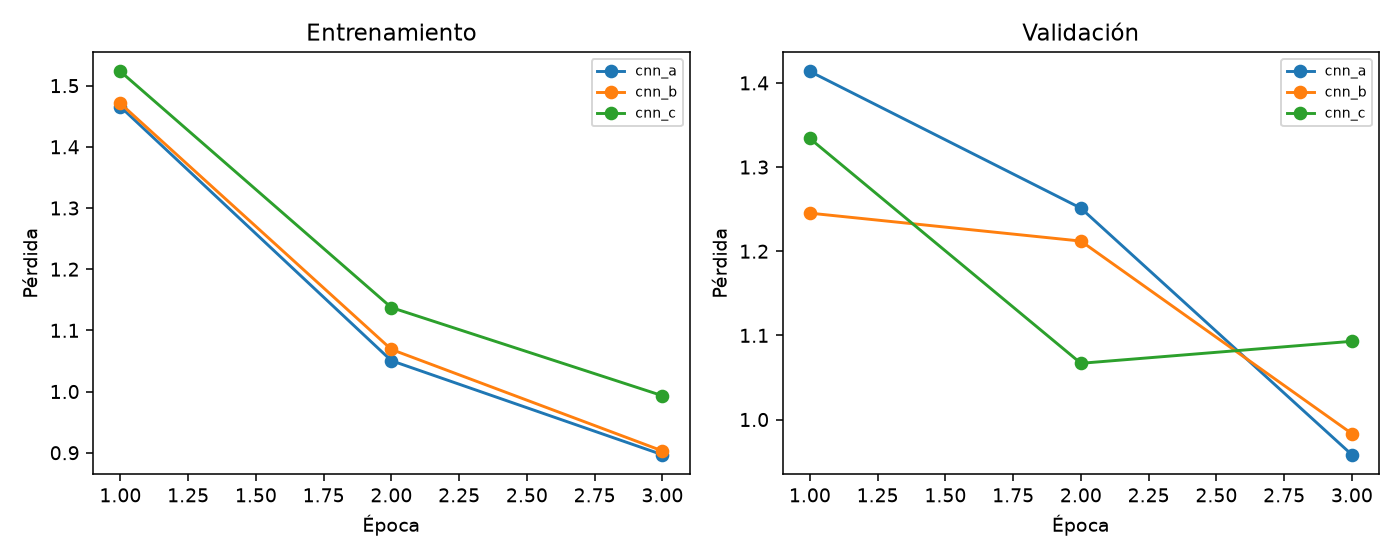

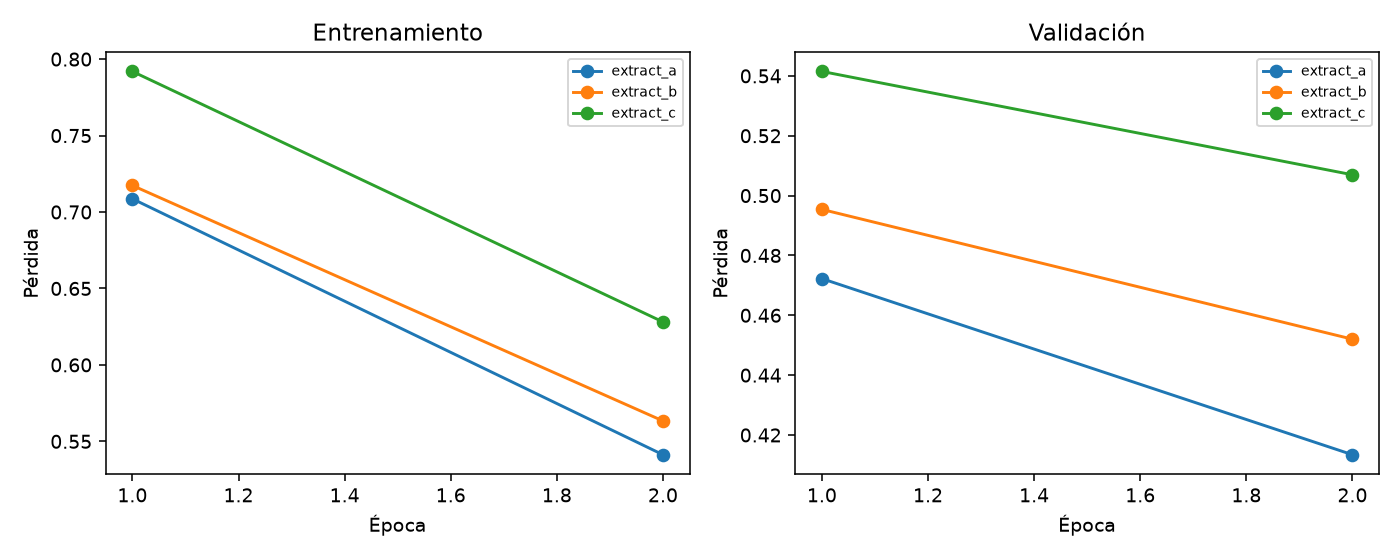

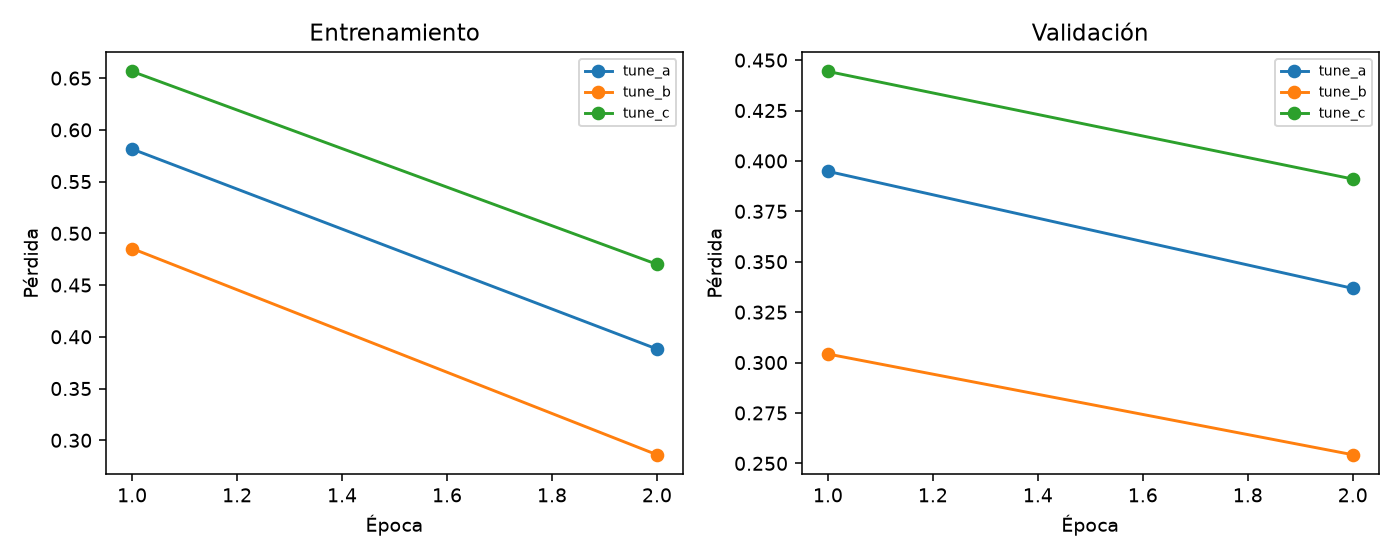

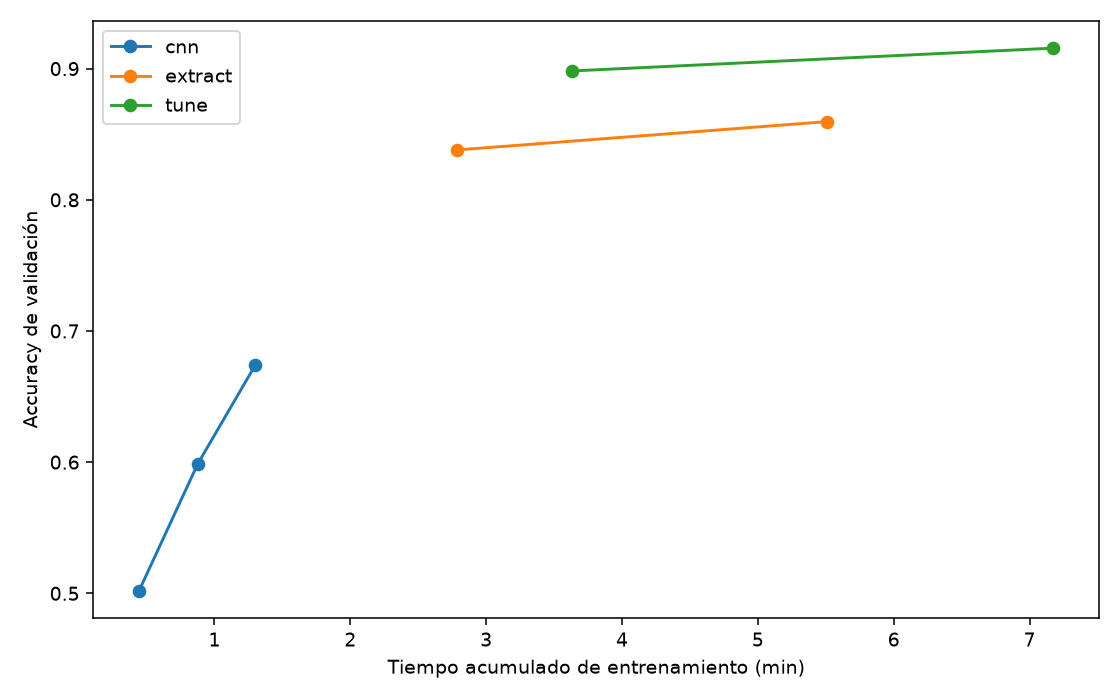

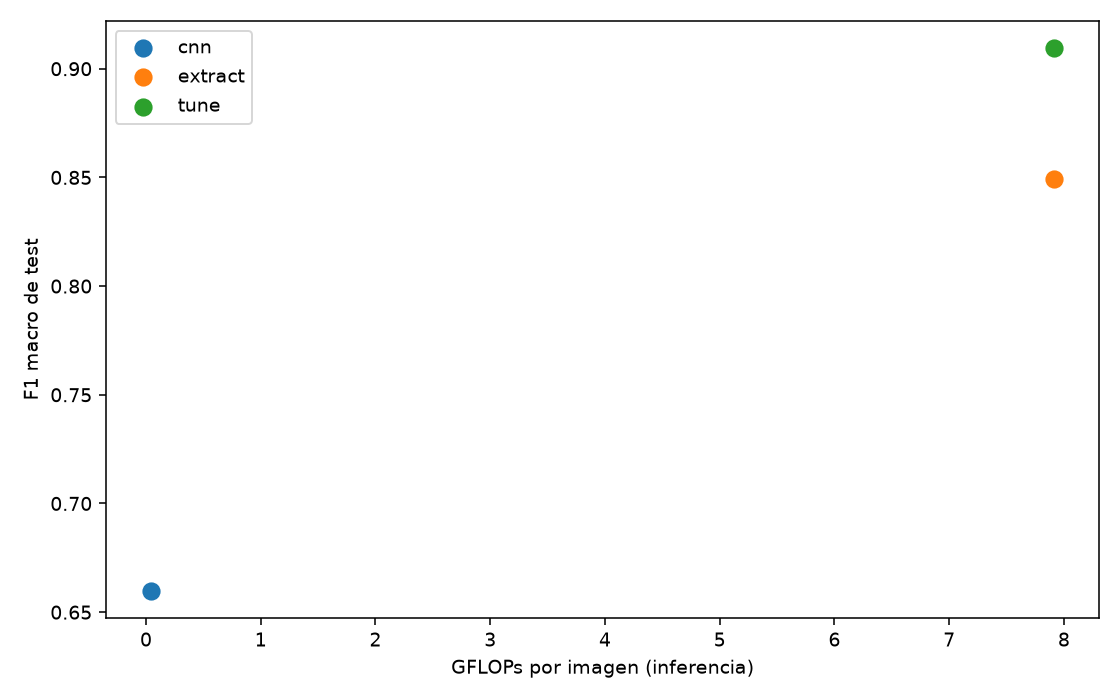

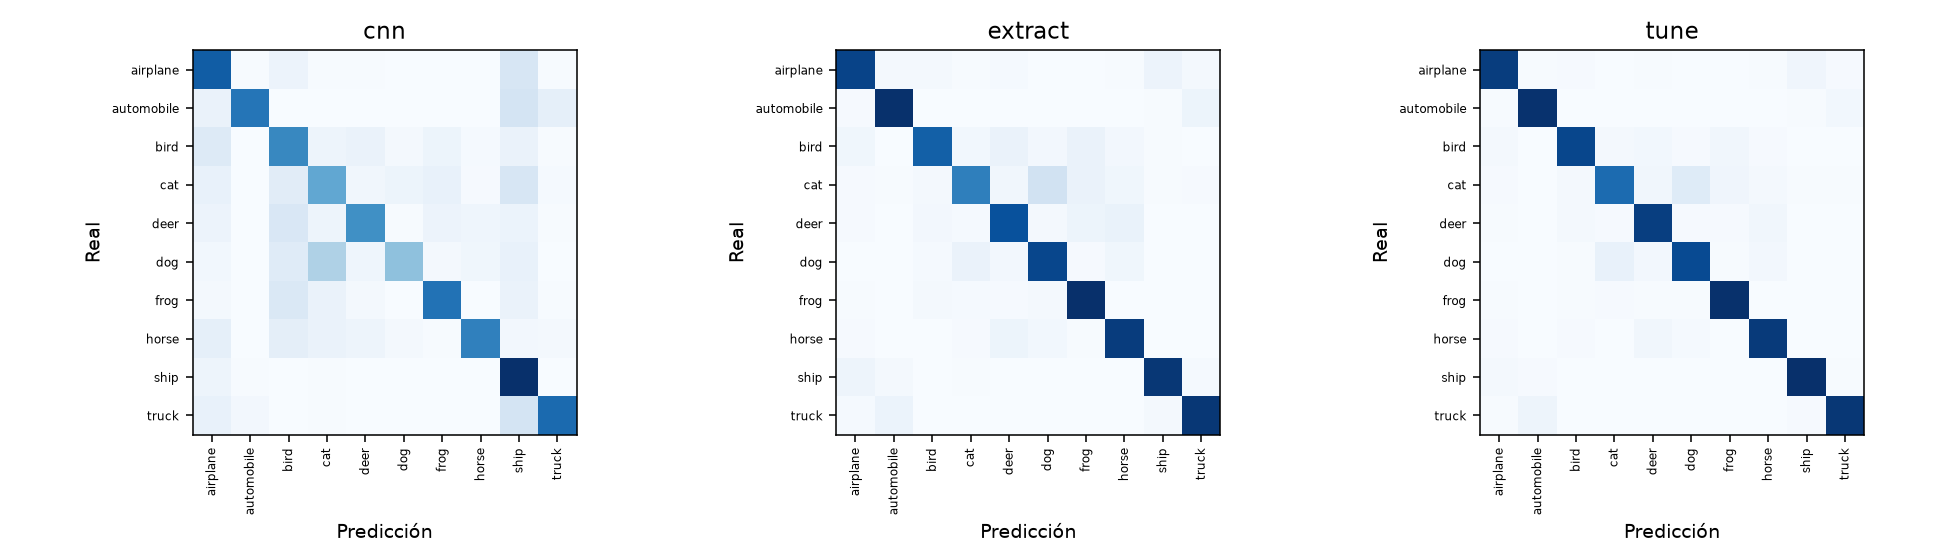

In [6]:
for filename in ('loss_cnn.png', 'loss_extract.png', 'loss_tune.png', 'accuracy_vs_time.png', 'f1_vs_flops.png', 'confusions.png'):
    display(Image(filename=str(RESULTS / filename)))